# VoxCeleb1-H: the dataset the experiment actually uses

Every figure needed to understand which audio the SST bracket evaluation of the pretrained models
(`configs/pretrained-resnet34-voxceleb-2s.yaml`, `configs/pretrained-w2vbert-voxceleb-2s.yaml`) is scored on:

1. **VoxCeleb1 as a whole**, the pool the extended utterances are drawn from.
2. **The VoxCeleb1-H trial list** (`list_test_hard2.txt`, cleaned) and its **original utterances**: count, lengths,
   utterances per speaker and video, trials per utterance. OS, SS and BS{b} score these, on every trial.
3. **The extended utterances**: each trial utterance followed by the other utterances of its video in file order
   (`src/experiment.py::_lazy_extended_trial_utterances`). GO{b}, GS{b}, GC{b} and OC{b} are cut from these.
4. **The trials GO/GS/GC/OC score**: both extended utterances at least as long as the largest gapped span (the
   smallest $b$'s), and not both from one video (`sst_shared_trials`, `sst_extended_utterances`).
5. **What the gapped window sees**: how much of its centered span comes from the trial utterance itself, and how
   many utterance boundaries it crosses.

Lengths are counted in feature frames exactly as the experiment counts them (`expected_frame_count` per file), per
front-end: WeSpeaker fbank (10 ms frames) and w2v-BERT 2.0 (20 ms frames). Every parameter comes from the two
config files. Nothing is featurized: only the cached `.sst-wav-index.tsv` sample counts and the trial lists are
read, so the notebook runs in a few minutes.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import ExperimentConfig
from src.data.lazy_features import expected_frame_count
from src.data.segments import gapped_span
from src.experiment import _gapped_trial_mask
from src.training.trainer import block_gap

# Set matplotlib style for print-friendly plots (white background)
plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.titlecolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'
plt.rcParams['text.color'] = 'black'
plt.rcParams['grid.color'] = 'gray'
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['legend.facecolor'] = 'white'
plt.rcParams['legend.edgecolor'] = 'black'

CONFIGS = {
    "WeSpeaker ResNet34": ROOT / "configs/pretrained-resnet34-voxceleb-2s.yaml",
    "w2v-BERT 2.0": ROOT / "configs/pretrained-w2vbert-voxceleb-2s.yaml",
}
HOP_FRACTION = 0.5  # extract_embeddings' default: OS/SS/BS windows overlap by half
configs = {name: ExperimentConfig.from_yaml(path) for name, path in CONFIGS.items()}
for config in configs.values():
    assert config.evaluation.sst_extended_utterances and config.evaluation.sst_shared_trials

vox1_root = Path(configs["WeSpeaker ResNet34"].voxceleb.root).expanduser()
SAMPLE_RATE = 16000

## Experiment parameters per front-end

The segment (2 s), the fixed gap between GO/GS blocks, the block sizes $b$ the configs test, and the span of the
gapped window per $b$: $\text{span}(b) = s + (\lceil s/b \rceil - 1)\,g$ frames, for segment length $s$ and gap
$g$. The largest span (at $b=2$) decides which trials GO/GS/GC/OC score.

In [2]:
def gapped_block_sizes(config):
    return sorted({int(s[2:]) for s in config.evaluation.test_strategies if s.startswith(("GO", "GS", "GC", "OC"))})


params = {}
rows = []
for name, config in configs.items():
    tf = config.transformation
    period = tf.frame_period_s
    segment = config.data.segment_length(tf)
    gap = round(config.evaluation.sst_gap_s / period)
    spans = {b: gapped_span(segment, b, block_gap(b, None, gap)) for b in gapped_block_sizes(config)}
    params[name] = dict(tf=tf, period=period, segment=segment, gap=gap, spans=spans, max_span=max(spans.values()),
                        step=max(int(HOP_FRACTION * segment), 1))
    for b, span in spans.items():
        rows.append({"model": name, "front-end": tf.type, "frame [ms]": period * 1000, "segment [frames]": segment,
                     "gap [frames]": gap, "gap [ms]": gap * period * 1000, "b": b, "block [ms]": tf.block_span_s(b) * 1000,
                     "span [frames]": span, "span [s]": span * period})
pd.DataFrame(rows).set_index(["model", "b"]).style.format(precision=1)

## 1. VoxCeleb1 as a whole

In [3]:
index = pd.read_csv(vox1_root / ".sst-wav-index.tsv", sep="\t", names=["path", "samples"])
index["speaker"] = index["path"].str.split("/").str[0]
index["video"] = index["path"].map(os.path.dirname)
index["seconds"] = index["samples"] / SAMPLE_RATE
index = index.sort_values("path").reset_index(drop=True)  # file order, as video_utterance_paths
index = index.set_index("path")

summary = pd.Series({
    "utterances": len(index),
    "speakers": index["speaker"].nunique(),
    "videos": index["video"].nunique(),
    "hours": index["seconds"].sum() / 3600,
    "utterance length: min [s]": index["seconds"].min(),
    "utterance length: median [s]": index["seconds"].median(),
    "utterance length: max [s]": index["seconds"].max(),
}, name="VoxCeleb1 (dev + test)")
summary.to_frame().style.format(precision=2)

,VoxCeleb1 (dev + test)
utterances,153516.00
speakers,1251.00
videos,22496.00
hours,351.60
utterance length: min [s],3.96
utterance length: median [s],6.48
utterance length: max [s],144.92


## 2. VoxCeleb1-H trials and their original utterances

In [4]:
def read_trials(path):
    trials = pd.read_csv(path, sep=" ", names=["label", "path1", "path2"])
    for k in (1, 2):
        trials[f"speaker{k}"] = trials[f"path{k}"].str.split("/").str[0]
        trials[f"video{k}"] = trials[f"path{k}"].map(os.path.dirname)
    trials["same video"] = trials["video1"] == trials["video2"]
    return trials


trials = read_trials(vox1_root / "list_test_hard2.txt")
trials_o = read_trials(vox1_root / "veri_test2.txt")


def trial_summary(trials):
    paths = pd.unique(trials[["path1", "path2"]].values.ravel())
    utterances = index.loc[paths]
    return pd.Series({
        "trials": len(trials),
        "target trials": int(trials["label"].sum()),
        "non-target trials": int((trials["label"] == 0).sum()),
        "same-video trials": int(trials["same video"].sum()),
        "same-video target trials": int((trials["same video"] & (trials["label"] == 1)).sum()),
        "utterances": len(paths),
        "speakers": utterances["speaker"].nunique(),
        "videos": utterances["video"].nunique(),
        "hours": utterances["seconds"].sum() / 3600,
    })


missing = set(pd.unique(trials[["path1", "path2"]].values.ravel())) - set(index.index)
assert not missing, f"{len(missing)} trial utterances missing from the index"
pd.DataFrame({"VoxCeleb1-H (reported)": trial_summary(trials),
              "VoxCeleb1-O (checkpoint selection, context)": trial_summary(trials_o)}).style.format(precision=1)

,VoxCeleb1-H (reported),"VoxCeleb1-O (checkpoint selection, context)"
trials,550894.0,37611.0
target trials,275488.0,18802.0
non-target trials,275406.0,18809.0
same-video trials,32778.0,2055.0
same-video target trials,32778.0,2055.0
utterances,137924.0,4708.0
speakers,1190.0,40.0
videos,21421.0,674.0
hours,316.2,10.8


VoxCeleb1-H pairs only speakers of the same nationality and gender, so its non-target trials are harder than
VoxCeleb1-O's. Below, *original utterances* are the unique utterances referenced by the VoxCeleb1-H list.

In [5]:
trial_paths = np.sort(pd.unique(trials[["path1", "path2"]].values.ravel()))
original = index.loc[trial_paths].copy()
original["trials"] = pd.concat([trials["path1"], trials["path2"]]).value_counts().reindex(original.index)

original["seconds"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("original utterance length [s]")

,original utterance length [s]
count,137924.000000
mean,8.252634
std,5.334310
min,3.960062
5%,4.120063
25%,4.920063
50%,6.480062
75%,9.520062
95%,18.520063
max,144.920063


In [6]:
LENGTH_S = 59.19  # s

def length_quantile(seconds):
    # The quantile a length sits at: the share of original utterances at least `seconds` long.
    return (seconds <= original["seconds"]).mean()


print(f"{length_quantile(LENGTH_S):.4%} of the original utterances are at least {LENGTH_S} s long "
      f"({(LENGTH_S <= original['seconds']).sum()} of {len(original)})")

0.0334% of the original utterances are at least 59.19 s long (46 of 137924)


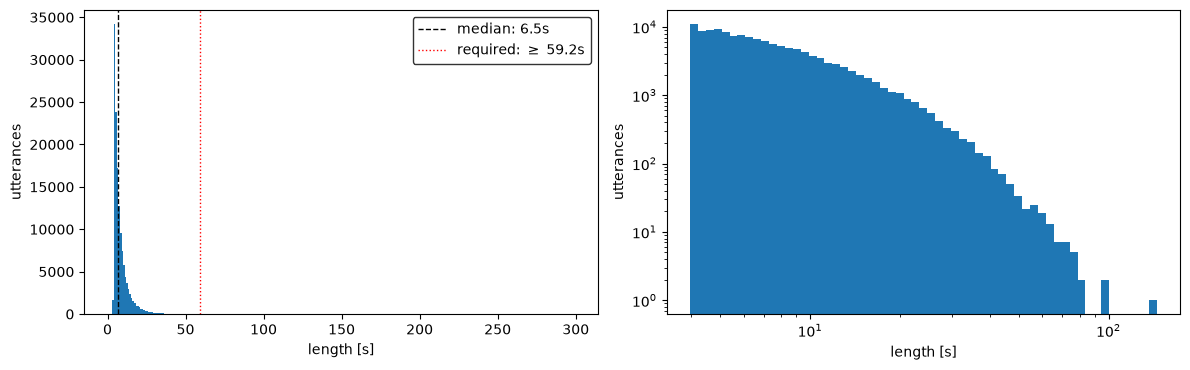

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.hist(original["seconds"], bins=np.arange(0, 300, 1), color="C0")
ax.axvline(original["seconds"].median(), color="k", ls="--", lw=1, label=f"median: {original['seconds'].median():.1f}s")
ax.axvline(original["seconds"].quantile(1. - 0.00032), color="r", ls=":", lw=1, label=f"required: $\\geq$ {LENGTH_S:.1f}s")
ax.set(xlabel="length [s]", ylabel="utterances")
ax.legend()
ax = axes[1]
ax.hist(original["seconds"], bins=np.geomspace(original["seconds"].min(), original["seconds"].max(), 60), color="C0")
ax.set(xscale="log", yscale="log", xlabel="length [s]", ylabel="utterances")
fig.tight_layout()

### Utterances per speaker and per video

In [8]:
per_speaker = original.groupby("speaker").agg(utterances=("seconds", "size"), videos=("video", "nunique"),
                                              seconds=("seconds", "sum"))
per_video = original.groupby("video").size().rename("utterances")
pd.DataFrame({
    "utterances per speaker": per_speaker["utterances"].describe(),
    "videos per speaker": per_speaker["videos"].describe(),
    "seconds per speaker": per_speaker["seconds"].describe(),
    "utterances per video": per_video.describe(),
}).style.format(precision=1)

,utterances per speaker,videos per speaker,seconds per speaker,utterances per video
count,1190.0,1190.0,1190.0,21421.0
mean,115.9,18.0,956.5,6.4
std,61.5,6.0,564.7,8.7
min,37.0,8.0,224.1,1.0
25%,67.0,13.0,528.1,2.0
50%,100.0,17.0,793.1,4.0
75%,147.0,22.0,1214.6,8.0
max,260.0,36.0,3680.1,165.0


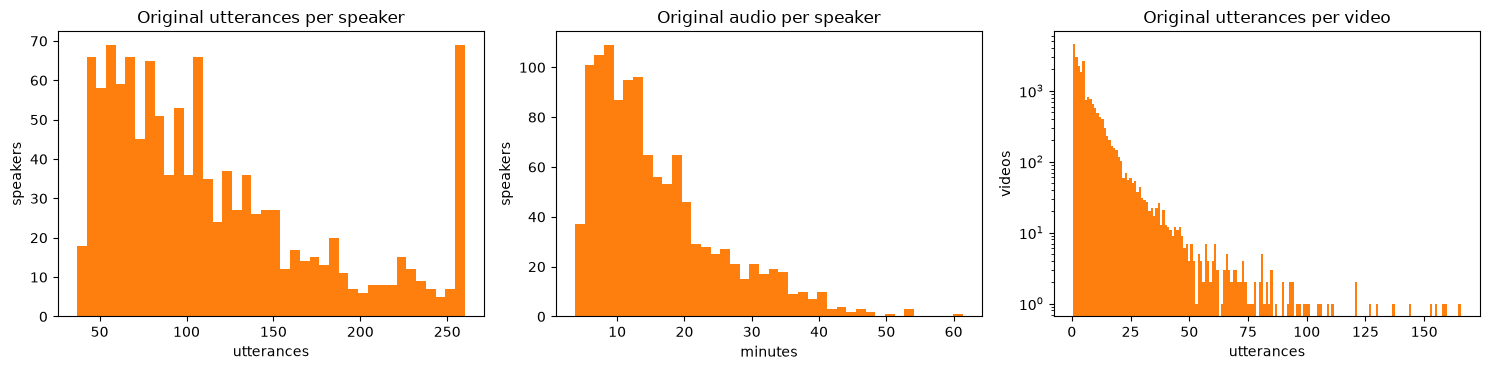

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(per_speaker["utterances"], bins=40, color="C1")
axes[0].set(xlabel="utterances", ylabel="speakers", title="Original utterances per speaker")
axes[1].hist(per_speaker["seconds"] / 60, bins=40, color="C1")
axes[1].set(xlabel="minutes", ylabel="speakers", title="Original audio per speaker")
counts = per_video.value_counts().sort_index()
axes[2].bar(counts.index, counts.values, width=1, color="C1")
axes[2].set(xlabel="utterances", ylabel="videos", yscale="log", title="Original utterances per video")
fig.tight_layout()

### Trials per utterance and per speaker

In [10]:
trials_per_speaker = pd.concat([trials["speaker1"], trials["speaker2"]]).value_counts()
pd.DataFrame({"trials per utterance": original["trials"].describe(),
              "trial sides per speaker": trials_per_speaker.describe()}).style.format(precision=1)

,trials per utterance,trial sides per speaker
count,137924.0,1190.0
mean,8.0,925.9
std,2.0,490.1
min,3.0,254.0
25%,7.0,540.2
50%,8.0,795.0
75%,9.0,1174.0
max,19.0,2110.0


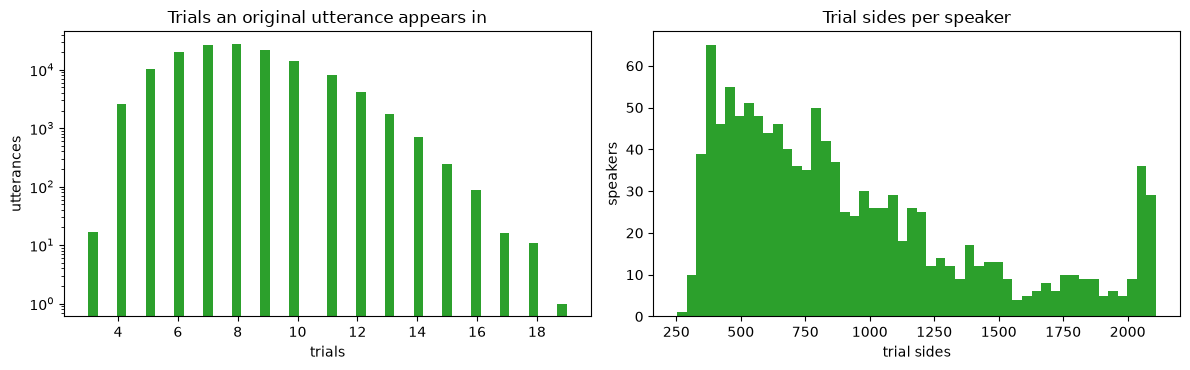

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(original["trials"], bins=50, color="C2")
axes[0].set(xlabel="trials", ylabel="utterances", yscale="log", title="Trials an original utterance appears in")
axes[1].hist(trials_per_speaker, bins=50, color="C2")
axes[1].set(xlabel="trial sides", ylabel="speakers", title="Trial sides per speaker")
fig.tight_layout()

### What OS, SS and BS{b} see

OS/SS/BS{b} cut $\lfloor (L - s)/h \rfloor + 1$ windows of $s$ frames, hop $h = s/2$, from each original utterance
of $L$ frames and average their embeddings; an utterance of at most $s$ frames gets none and its trials can't be
scored. Every trial of the list is scored if no utterance is that short.

In [12]:
for name, p in params.items():
    original[f"frames {name}"] = [expected_frame_count(n, p["tf"]) for n in original["samples"]]

rows, windows = [], {}
for name, p in params.items():
    frames = original[f"frames {name}"]
    windows[name] = np.where(frames > p["segment"], (frames - p["segment"]) // p["step"] + 1, 0)
    short = set(original.index[frames <= p["segment"]])
    scored = ~(trials["path1"].isin(short) | trials["path2"].isin(short))
    rows.append({"model": name, "utterances too short": len(short), "OS/SS/BS trials scored": int(scored.sum()),
                 "of which target": int(trials.loc[scored, "label"].sum()),
                 "windows per utterance: median": np.median(windows[name]),
                 "windows per utterance: max": windows[name].max(), "windows total": windows[name].sum()})
pd.DataFrame(rows).set_index("model")

,utterances too short,OS/SS/BS trials scored,of which target,windows per utterance: median,windows per utterance: max,windows total
model,,,,,,
WeSpeaker ResNet34,0,550894,275488,5.0,146,956628
w2v-BERT 2.0,0,550894,275488,5.0,146,956628


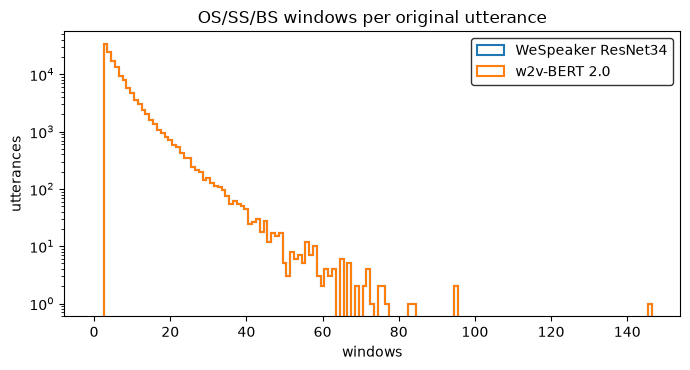

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for name in params:
    ax.hist(windows[name], bins=np.arange(0, windows[name].max() + 2) - 0.5, histtype="step", lw=1.5, label=name)
ax.set(xlabel="windows", ylabel="utterances", yscale="log", title="OS/SS/BS windows per original utterance")
ax.legend()
fig.tight_layout()

## 3. Extended utterances

The extended utterance of a trial utterance is that utterance followed by every other VoxCeleb1 utterance of its
video, in file order, each featurized on its own. Its length in frames is the sum of its parts' frames, so it is the
same for every utterance of one video.

In [14]:
video_utterances = index.groupby("video").size()
original["video utterances"] = video_utterances.reindex(original["video"]).values
original["extended seconds"] = index.groupby("video")["seconds"].sum().reindex(original["video"]).values
file_frames = {}  # frames of every VoxCeleb1 file, per front-end
for name, p in params.items():
    frames = pd.Series([expected_frame_count(n, p["tf"]) for n in index["samples"]], index=index.index)
    file_frames[name] = frames
    original[f"extended frames {name}"] = frames.groupby(index["video"]).sum().reindex(original["video"]).values

pd.DataFrame({
    "original length [s]": original["seconds"].describe(),
    "extended length [s]": original["extended seconds"].describe(),
    "extension factor": (original["extended seconds"] / original["seconds"]).describe(),
    "utterances in extended": original["video utterances"].describe(),
}).style.format(precision=2)

,original length [s],extended length [s],extension factor,utterances in extended
count,137924.00,137924.00,137924.00,137924.00
mean,8.25,166.82,23.92,19.65
std,5.33,228.30,36.16,26.15
min,3.96,3.96,1.00,1.00
25%,4.92,43.36,5.77,6.00
50%,6.48,92.88,12.25,11.00
75%,9.52,188.96,26.00,21.00
max,144.92,1940.29,489.97,239.00


In [15]:
LENGTH_S = 59.19  # s

def length_quantile(seconds):
    # The quantile a length sits at: the share of original utterances at least `seconds` long.
    return (seconds <= original["extended seconds"]).mean()


print(f"{length_quantile(LENGTH_S):.2%} of the extended utterances are at least {LENGTH_S} s long "
      f"({(LENGTH_S <= original['extended seconds']).sum()} of {len(original)})")

65.95% of the extended utterances are at least 59.19 s long (90962 of 137924)


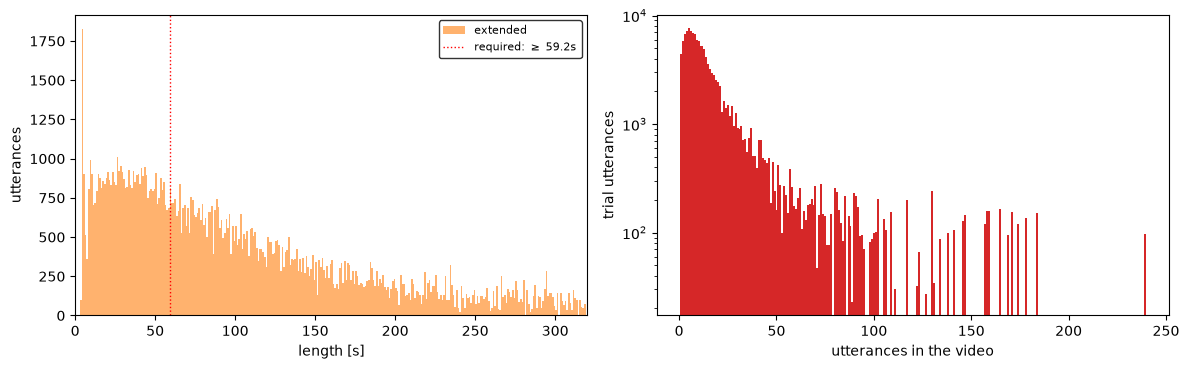

In [16]:
bins=np.arange(0, 320, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
#ax.hist(original["seconds"], bins=bins, alpha=0.6, label="original")
ax.hist(original["extended seconds"], bins=bins, alpha=0.6, label="extended", color='C1')
ax.axvline(original["extended seconds"].quantile(1. - 0.6595), color="r", ls=":", lw=1, label=f"required: $\\geq$ {LENGTH_S:.1f}s")
ax.set(xlabel="length [s]", ylabel="utterances", xlim=(0, original["extended seconds"].quantile(0.85)))  # the longest 10% of extended utterances are cut off
ax.legend(fontsize=8)
ax.set_xlim(0, 320)
ax = axes[1]
counts = original["video utterances"].value_counts().sort_index()
ax.bar(counts.index, counts.values, width=1, color="C3")
ax.set(xlabel="utterances in the video", ylabel="trial utterances", yscale="log")
fig.tight_layout()

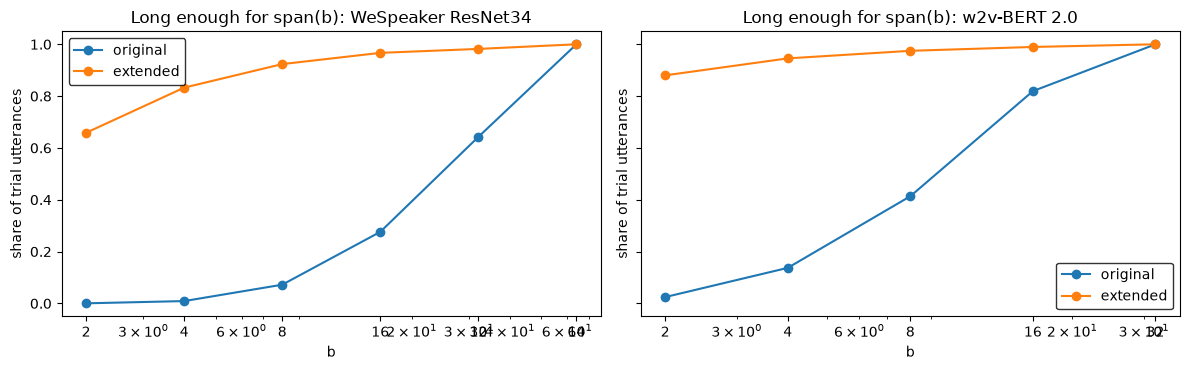

In [17]:
# Share of trial utterances at least as long as each span: original vs. extended.
fig, axes = plt.subplots(1, len(params), figsize=(6 * len(params), 3.8), sharey=True)
for ax, (name, p) in zip(axes, params.items()):
    b_values = list(p["spans"])
    spans = [p["spans"][b] for b in b_values]
    for kind, column in (("original", f"frames {name}"), ("extended", f"extended frames {name}")):
        ax.plot(b_values, [(original[column] >= span).mean() for span in spans], marker="o", label=kind)
    ax.set(xscale="log", xlabel="b", ylabel="share of trial utterances", title=f"Long enough for span(b): {name}")
    ax.set_xticks(b_values, b_values)
    ax.legend()
fig.tight_layout()

## 4. Trials scored by GO{b}, GS{b}, GC{b} and OC{b}

A trial is scored if both its extended utterances are at least `max_span` frames long and its two utterances come from
different videos (same-video extended utterances would share audio). With `sst_shared_trials` every $b$ uses this one
set; the per-$b$ counts without sharing are shown for comparison.

In [18]:
def gapped_mask(name, span, extended=True, exclude_same_video=True):
    column = f"{'extended ' if extended else ''}frames {name}"
    length = original[column]
    return ((length.reindex(trials["path1"]).values >= span) & (length.reindex(trials["path2"]).values >= span)
            & ~(exclude_same_video & trials["same video"].values))


# The trials used must be exactly those the experiment scores.
trial_pairs = list(trials[["label", "path1", "path2"]].itertuples(index=False, name=None))
for name, p in params.items():
    lengths = original[f"extended frames {name}"].to_dict()
    assert (gapped_mask(name, p["max_span"]) == _gapped_trial_mask(trial_pairs, lengths, p["max_span"], True)).all()

rows = []
for name, p in params.items():
    for label, span, extended in [("shared, extended (used)", p["max_span"], True),
                                  ("shared, original only", p["max_span"], False),
                                  *[(f"b={b} only, extended", span, True) for b, span in p["spans"].items()]]:
        mask = gapped_mask(name, span, extended)
        kept = trials[mask]
        rows.append({"model": name, "trial set": label, "span [s]": span * p["period"], "trials": int(mask.sum()),
                     "share of trials": mask.mean(), "target": int(kept["label"].sum()),
                     "non-target": int((kept["label"] == 0).sum()), "target share": kept["label"].mean(),
                     "speakers": pd.unique(kept[["speaker1", "speaker2"]].values.ravel()).size,
                     "utterances": pd.unique(kept[["path1", "path2"]].values.ravel()).size})
gapped_trials = pd.DataFrame(rows).set_index(["model", "trial set"])
gapped_trials.style.format({"span [s]": "{:.1f}", "share of trials": "{:.1%}", "target share": "{:.1%}"})

### OS vs. GO/GS trial sets side by side

In [19]:
rows = []
for name, p in params.items():
    used = gapped_mask(name, p["max_span"])
    for label, mask in (("all (OS, SS, BS)", np.ones(len(trials), bool)), ("GO/GS/GC/OC", used)):
        kept = trials[mask]
        utterances = original.loc[pd.unique(kept[["path1", "path2"]].values.ravel())]
        rows.append({"model": name, "trials": label, "count": int(mask.sum()), "target share": kept["label"].mean(),
                     "utterances": len(utterances), "speakers": utterances["speaker"].nunique(),
                     "videos": utterances["video"].nunique(),
                     "median original length [s]": utterances["seconds"].median(),
                     "median extended length [s]": utterances["extended seconds"].median()})
pd.DataFrame(rows).set_index(["model", "trials"]).style.format(precision=2)

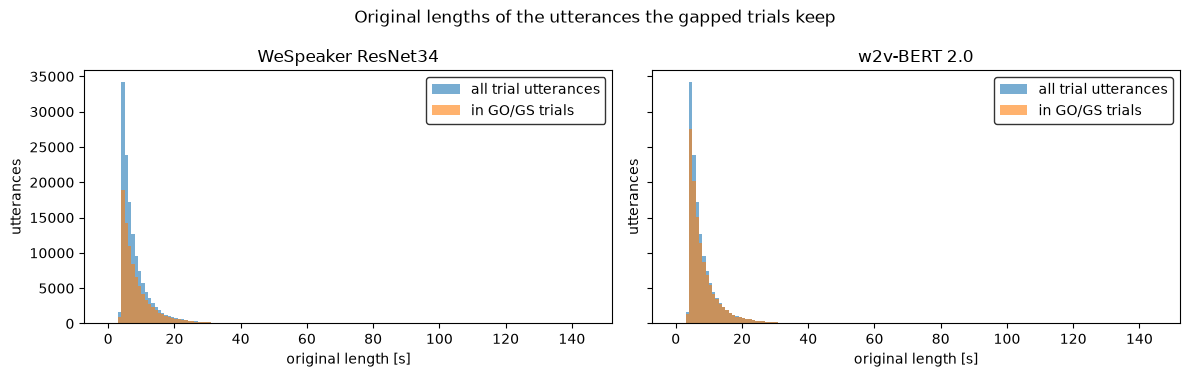

In [20]:
fig, axes = plt.subplots(1, len(params), figsize=(6 * len(params), 3.8), sharey=True)
for ax, (name, p) in zip(axes, params.items()):
    used = gapped_mask(name, p["max_span"])
    kept_paths = pd.unique(trials.loc[used, ["path1", "path2"]].values.ravel())
    bins = np.arange(0, original["seconds"].max() + 1, 1)
    ax.hist(original["seconds"], bins=bins, alpha=0.6, label="all trial utterances")
    ax.hist(original.loc[kept_paths, "seconds"], bins=bins, alpha=0.6, label="in GO/GS trials")
    ax.set(xlabel="original length [s]", ylabel="utterances", title=name)
    ax.legend()
fig.suptitle("Original lengths of the utterances the gapped trials keep")
fig.tight_layout()

## 5. What the gapped window sees

The GO/GS window takes one span, centered in the *extended* utterance (position 0.5), and keeps its blocks.
Since the trial utterance comes first, the centered span can lie partly or wholly in *other* utterances of the
video. Below: the share of the GO{b} input frames that come from the trial utterance itself, and how many utterance
boundaries (joins of separately featurized parts) the span crosses, over the utterances of the scored trials.

In [21]:
# Every file's video and its position in the video's file order, and per front-end each video's file frames.
position = index.groupby("video").cumcount()
video_frames = {name: {video: f.values for video, f in file_frames[name].groupby(index["video"])} for name in params}


def window_stats(name, b, paths):
    # Per utterance: the share of GO{b}'s input frames inside the trial utterance (the first part of its extended
    # utterance), and the part boundaries strictly inside the span. The span starts at round(0.5 * (total - span)),
    # as gapped_segment at position 0.5; its block frames are fixed offsets from that start.
    p = params[name]
    span, segment, gap = p["spans"][b], p["segment"], p["gap"]
    offsets = np.concatenate([np.arange(i * (b + gap), i * (b + gap) + min(b, segment - i * b))
                              for i in range(-(-segment // b))])
    own_share, boundaries = [], []
    for path, video, k in zip(paths, index.loc[paths, "video"], position.loc[paths]):
        frames = video_frames[name][video]
        lengths = np.concatenate([frames[k:k + 1], frames[:k], frames[k + 1:]])
        start = round(0.5 * (lengths.sum() - span))
        own_share.append(np.mean(start + offsets < lengths[0]))
        ends = np.cumsum(lengths)[:-1]
        boundaries.append(int(((ends > start) & (ends < start + span)).sum()))
    return pd.DataFrame({"model": name, "b": b, "path": paths, "own share": own_share, "boundaries in span": boundaries})


parts = []
for name, p in params.items():
    used = gapped_mask(name, p["max_span"])
    paths = pd.unique(trials.loc[used, ["path1", "path2"]].values.ravel())
    parts += [window_stats(name, b, paths) for b in p["spans"]]
window = pd.concat(parts, ignore_index=True)
window.groupby(["model", "b"]).agg(
    utterances=("path", "size"),
    own_share_mean=("own share", "mean"),
    own_share_zero=("own share", lambda s: (s == 0).mean()),
    own_share_full=("own share", lambda s: (s == 1).mean()),
    boundaries_median=("boundaries in span", "median"),
    boundaries_max=("boundaries in span", "max"),
).style.format({"own_share_mean": "{:.1%}", "own_share_zero": "{:.1%}", "own_share_full": "{:.1%}"})

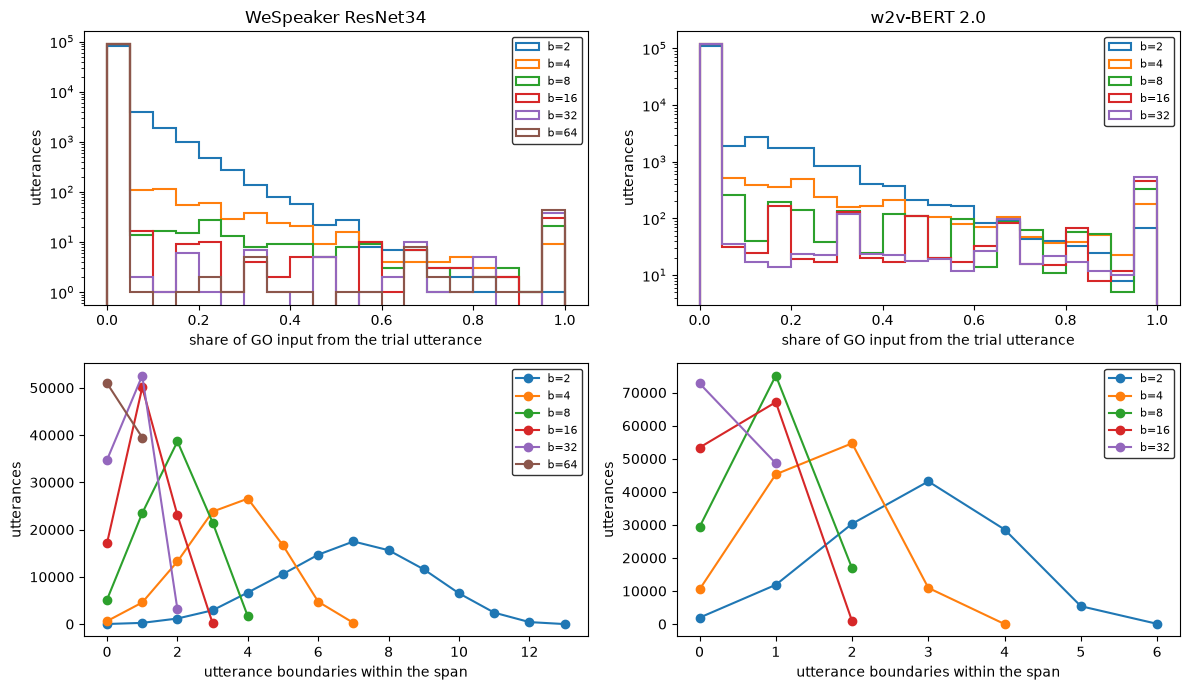

In [22]:
fig, axes = plt.subplots(2, len(params), figsize=(6 * len(params), 7))
for col, name in enumerate(params):
    w = window[window["model"] == name]
    for b, group in w.groupby("b"):
        axes[0, col].hist(group["own share"], bins=np.linspace(0, 1, 21), histtype="step", lw=1.5, label=f"b={b}")
        counts = group["boundaries in span"].value_counts().sort_index()
        axes[1, col].plot(counts.index, counts.values, marker="o", label=f"b={b}")
    axes[0, col].set(xlabel="share of GO input from the trial utterance", ylabel="utterances", yscale="log", title=name)
    axes[1, col].set(xlabel="utterance boundaries within the span", ylabel="utterances")
    axes[0, col].legend(fontsize=8)
    axes[1, col].legend(fontsize=8)
fig.tight_layout()

**Reading.** Because the trial utterance comes first and the span is centered in the whole extended utterance, at
small $b$ (long spans) the span usually starts after the trial utterance has ended. GO/GS/GC/OC then mostly score
*other* utterances of the same video (same speaker, same session), not the trial utterance itself, and the span
crosses several boundaries between separately featurized parts. The shares above quantify this per $b$.

## 6. Reused audio

Every trial utterance gets its own extended utterance, but all extended utterances of one video consist of the same
files, only with a different one moved to the front. They also share one total length, so the centered span sits at
the same place in each. Beyond the files $u_1 \dots u_k$ the layout of $u_k$'s extended utterance equals the plain file
order, so different trial utterances of one video often get the very same GO/GS input, and otherwise inputs cut from
largely the same files.

Per model and $b$, over the utterances of the scored trials:

- **distinct inputs**: utterances whose GO{b} input (as source frames: file and frame within it) differs from every other;
- **as plain file order**: share whose input equals that of the video's files in plain file order;
- **frame reuse**: input frames in total over distinct source frames, i.e. how often each source frame is fed on average;
- **distinct trials**: trials left after merging those whose two inputs are identical.

In [23]:
file_id = pd.Series(np.arange(len(index)), index=index.index)  # index is sorted by path: a video's files are contiguous
first_file = file_id.groupby(index["video"]).min()


def go_inputs(name, b, paths):
    # Per utterance, GO{b}'s input as source-frame ids (file id * 2**32 + frame in the file), for the experiment's
    # part order (the utterance first) and for the video's plain file order.
    p = params[name]
    span, segment, gap = p["spans"][b], p["segment"], p["gap"]
    offsets = np.concatenate([np.arange(i * (b + gap), i * (b + gap) + min(b, segment - i * b))
                              for i in range(-(-segment // b))])

    def sources(frames, ids, order):
        ends = np.cumsum(frames[order])
        positions = round(0.5 * (ends[-1] - span)) + offsets  # gapped_segment at position 0.5
        part = np.searchsorted(ends, positions, side="right")
        return ids[order][part] * 2**32 + positions - (ends[part] - frames[order][part])

    experiment, natural = [], []
    for path, video, k in zip(paths, index.loc[paths, "video"], position.loc[paths]):
        frames = video_frames[name][video]
        ids = first_file[video] + np.arange(len(frames))
        experiment.append(sources(frames, ids, np.r_[k, 0:k, k + 1:len(frames)]))
        natural.append(sources(frames, ids, np.arange(len(frames))))
    return experiment, natural


rows = []
for name, p in params.items():
    used = trials[gapped_mask(name, p["max_span"])]
    paths = pd.unique(used[["path1", "path2"]].values.ravel())
    for b in p["spans"]:
        experiment, natural = go_inputs(name, b, paths)
        key = dict(zip(paths, (x.tobytes() for x in experiment)))
        pairs = {frozenset((key[a], key[c])) for a, c in zip(used["path1"], used["path2"])}
        total = sum(len(x) for x in experiment)
        distinct_frames = np.unique(np.concatenate(experiment)).size
        rows.append({"model": name, "b": b, "utterances": len(paths), "distinct inputs": len(set(key.values())),
                     "as plain file order": np.mean([np.array_equal(e, n) for e, n in zip(experiment, natural)]),
                     "input frames": total, "distinct source frames": distinct_frames,
                     "frame reuse": total / distinct_frames, "trials": len(used), "distinct trials": len(pairs)})
reuse = pd.DataFrame(rows).set_index(["model", "b"])
reuse["distinct inputs share"] = reuse["distinct inputs"] / reuse["utterances"]
reuse["distinct trials share"] = reuse["distinct trials"] / reuse["trials"]
reuse.style.format({"as plain file order": "{:.1%}", "frame reuse": "{:.2f}", "distinct inputs share": "{:.1%}",
                    "distinct trials share": "{:.1%}"})

### Extended utterances if each utterance is used at most once

Two ways to build extended utterances in which no file appears twice, over the videos of the VoxCeleb1-H trial
utterances:

- **one per video**: all files of the video, in file order;
- **disjoint chunks**: the video's files in file order, split greedily into consecutive chunks of at least the
  model's largest span (`max_span`); a remainder shorter than that joins the last chunk.

A trial utterance then maps to the extended utterance (unit) that contains it. A trial is kept if both units are at
least `max_span` frames long and come from different videos, and trials mapping to the same pair of units count once.

In [24]:
trial_videos = original["video"].unique()
video_files = {video: list(files) for video, files in index.groupby("video").groups.items()}


def no_reuse_units(name, chunked):
    # {file: unit id} and per unit (video, speaker, frames, files), for the video's files in file order: whole, or
    # chunked greedily into runs of at least max_span frames (a shorter remainder joins the last chunk).
    span = params[name]["max_span"]
    unit_of, units = {}, []
    for video in trial_videos:
        files, frames = video_files[video], video_frames[name][video]
        chunks, current, length = [], [], 0
        for f, n in zip(files, frames):
            current.append(f)
            length += n
            if chunked and length >= span:
                chunks.append((current, length))
                current, length = [], 0
        if current:
            if chunks:
                chunks[-1] = (chunks[-1][0] + current, chunks[-1][1] + length)
            else:
                chunks.append((current, length))
        for files_, length_ in chunks:
            unit_of.update({f: len(units) for f in files_})
            units.append({"video": video, "speaker": video.split("/")[0], "frames": length_, "files": len(files_)})
    return unit_of, pd.DataFrame(units)


rows, unit_tables = [], {}
for name, p in params.items():
    span = p["max_span"]
    for variant, chunked in (("one per video", False), ("disjoint chunks", True)):
        unit_of, units = no_reuse_units(name, chunked)
        units["seconds"] = units["frames"] * p["period"]
        units["long enough"] = units["frames"] >= span
        unit_tables[name, variant] = units
        u1, u2 = trials["path1"].map(unit_of).values, trials["path2"].map(unit_of).values
        ok = units["long enough"].values
        keep = ok[u1] & ok[u2] & ~trials["same video"].values
        pairs = pd.DataFrame({"u": np.minimum(u1, u2)[keep], "v": np.maximum(u1, u2)[keep],
                              "label": trials["label"].values[keep]}).drop_duplicates()
        qualifying = units[units["long enough"]]
        per_speaker = qualifying.groupby("speaker").size()
        rows.append({"model": name, "variant": variant, "span [s]": span * p["period"], "units": len(units),
                     "long enough": len(qualifying), "median length [s]": qualifying["seconds"].median(),
                     "speakers": len(per_speaker), "speakers with >= 2 units": int((per_speaker >= 2).sum()),
                     "units per speaker (median)": per_speaker.median(),
                     "trials (distinct unit pairs)": len(pairs), "target": int(pairs["label"].sum()),
                     "non-target": int((pairs["label"] == 0).sum())})
pd.DataFrame(rows).set_index(["model", "variant"]).style.format(precision=1)

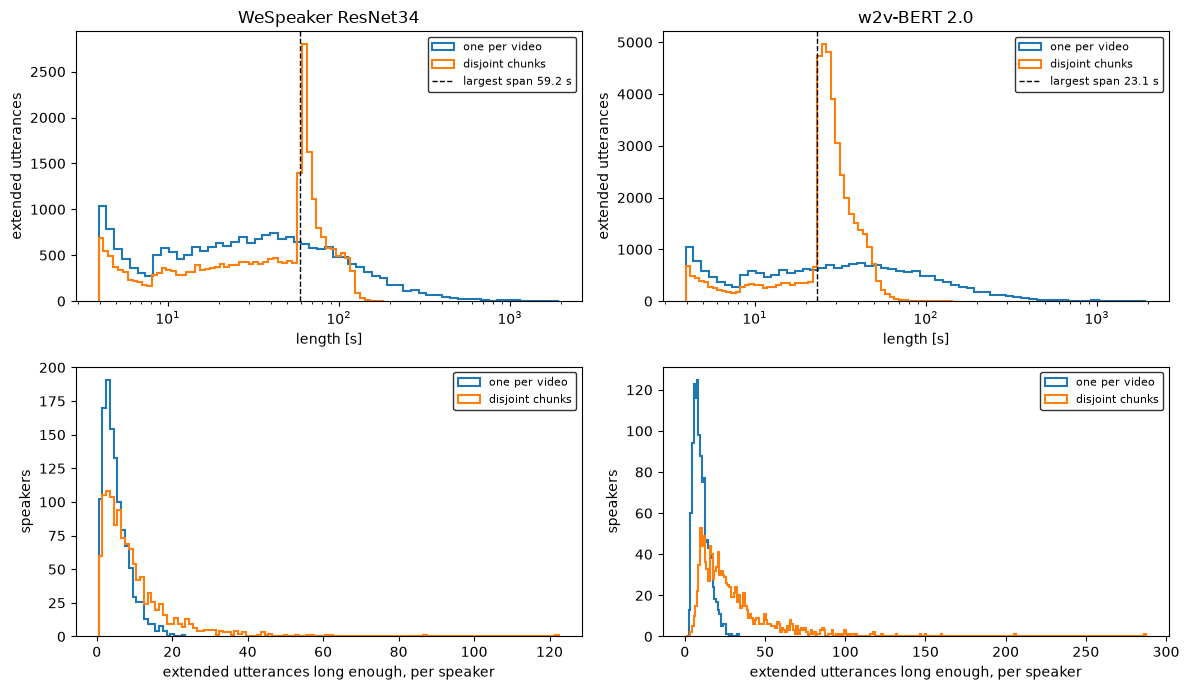

In [25]:
fig, axes = plt.subplots(2, len(params), figsize=(6 * len(params), 7))
for col, (name, p) in enumerate(params.items()):
    span_s = p["max_span"] * p["period"]
    for variant, color in (("one per video", "C0"), ("disjoint chunks", "C1")):
        units = unit_tables[name, variant]
        qualifying = units[units["long enough"]]
        axes[0, col].hist(units["seconds"], bins=np.geomspace(units["seconds"].min(), units["seconds"].max(), 60),
                          histtype="step", lw=1.5, color=color, label=variant)
        counts = qualifying.groupby("speaker").size()
        axes[1, col].hist(counts, bins=np.arange(1, counts.max() + 2) - 0.5, histtype="step", lw=1.5, color=color,
                          label=variant)
    axes[0, col].axvline(span_s, color="k", ls="--", lw=1, label=f"largest span {span_s:.1f} s")
    axes[0, col].set(xscale="log", xlabel="length [s]", ylabel="extended utterances", title=name)
    axes[1, col].set(xlabel="extended utterances long enough, per speaker", ylabel="speakers")
    axes[0, col].legend(fontsize=8)
    axes[1, col].legend(fontsize=8)
fig.tight_layout()

## Summary

In [26]:
rows = {}
for name, p in params.items():
    used = gapped_mask(name, p["max_span"])
    w = window[(window["model"] == name) & (window["b"] == min(p["spans"]))]
    rows[name] = {
        "VoxCeleb1-H trials (OS/SS/BS)": len(trials),
        "  target / non-target (all)": f"{trials['label'].sum()} / {(trials['label'] == 0).sum()}",
        "original utterances": len(original),
        "speakers": original["speaker"].nunique(),
        "videos": original["video"].nunique(),
        "median original length [s]": round(original["seconds"].median(), 2),
        "median extended length [s]": round(original["extended seconds"].median(), 2),
        "segment [s]": p["segment"] * p["period"],
        "gap [ms]": p["gap"] * p["period"] * 1000,
        "largest span [s]": round(p["max_span"] * p["period"], 2),
        "GO/GS/GC/OC trials": int(used.sum()),
        "  target / non-target (GO/GS)": f"{trials.loc[used, 'label'].sum()} / {(trials.loc[used, 'label'] == 0).sum()}",
        "  same-video trials excluded": int(trials["same video"].sum()),
        "  utterances": pd.unique(trials.loc[used, ["path1", "path2"]].values.ravel()).size,
        "  speakers": pd.unique(trials.loc[used, ["speaker1", "speaker2"]].values.ravel()).size,
        "GO input from the trial utterance at smallest b (mean)": f"{w['own share'].mean():.1%}",
        "  utterances whose GO input has none of it": f"{(w['own share'] == 0).mean():.1%}",
        "distinct GO inputs at smallest b": int(reuse.loc[(name, min(p["spans"])), "distinct inputs"]),
        "distinct GO trials at smallest b": int(reuse.loc[(name, min(p["spans"])), "distinct trials"]),
        "no reuse, one per video: long enough": int(unit_tables[name, "one per video"]["long enough"].sum()),
        "no reuse, disjoint chunks: long enough": int(unit_tables[name, "disjoint chunks"]["long enough"].sum()),
    }
pd.DataFrame(rows)

,WeSpeaker ResNet34,w2v-BERT 2.0
VoxCeleb1-H trials (OS/SS/BS),550894,550894
target / non-target (all),275488 / 275406,275488 / 275406
original utterances,137924,137924
speakers,1190,1190
videos,21421,21421
median original length [s],6.48,6.48
median extended length [s],92.88,92.88
segment [s],1.96,1.96
gap [ms],590.0,440.0
largest span [s],59.19,23.08
